# Example: one Bitcoin 5-minute market

On Polymarket, each "Bitcoin Up or Down" market covers 5 minutes.
**Up** wins if Bitcoin ends the 5 minutes higher than it started, otherwise **Down** wins.
A price of 0.70 for Up means the market thinks there is about a 70% chance of Up.

In [1]:
import sys
sys.path.append("../src")  # so Python finds data.py and plotting.py

import matplotlib.pyplot as plt
import data
import plotting

## 1. The market

Pick when the 5-minute window starts (UTC).

In [2]:
window_start = "2026-10-20 08:55"

market = data.get_market(data.btc_5m_slug(window_start))
print(market["question"])
print("Winner:", market["winner"])

Bitcoin Up or Down - October 20, 4:55AM-5:00AM ET
Winner: Up


## 2. Prices

Two sources:
- `get_btc_5m_prices`: one price per minute (only 5 points in the window).
- `get_trades`: every single trade, to the second.

In [3]:
prices = data.get_btc_5m_prices(window_start)
prices

,timestamp,up,down
0,2026-10-20 08:55:00+00:00,0.475,0.525
1,2026-10-20 08:56:00+00:00,0.495,0.505
2,2026-10-20 08:57:00+00:00,0.245,0.815
3,2026-10-20 08:58:00+00:00,0.655,0.345
4,2026-10-20 08:59:00+00:00,0.965,0.035


In [4]:
trades = data.get_trades(market["condition_id"])

# Keep trades in the "Up" token during the 5-minute window.
in_window = trades["timestamp"] >= market["window_start"]
up_trades = trades[in_window & (trades["outcome"] == "Up")]
print(len(up_trades), "Up trades in the window")
up_trades.head()

891 Up trades in the window


,timestamp,outcome,side,price,size
90,2026-10-20 08:55:02+00:00,Up,BUY,0.48,5.00
92,2026-10-20 08:55:04+00:00,Up,BUY,0.48,5.00
93,2026-10-20 08:55:04+00:00,Up,BUY,0.48,7.50
95,2026-10-20 08:55:04+00:00,Up,BUY,0.48,16.25
98,2026-10-20 08:55:07+00:00,Up,BUY,0.50,5.08


## 3. Plot

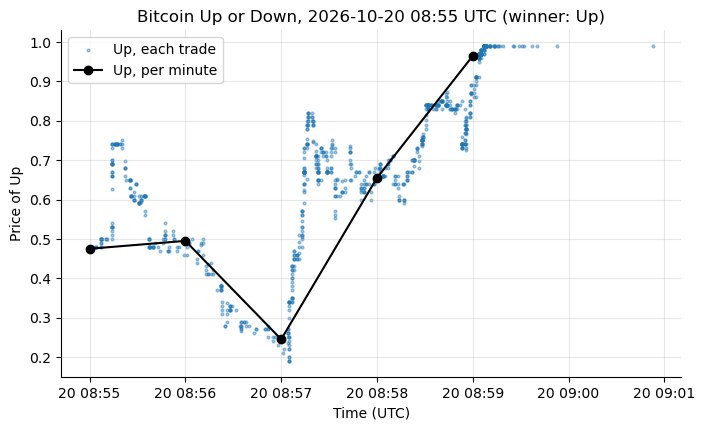

In [5]:
plotting.setup_style()

plt.scatter(up_trades["timestamp"], up_trades["price"], s=4, alpha=0.4, label="Up, each trade")
plt.plot(prices["timestamp"], prices["up"], color="black", marker="o", label="Up, per minute")
plt.title("Bitcoin Up or Down, " + window_start + " UTC (winner: " + market["winner"] + ")")
plt.xlabel("Time (UTC)")
plt.ylabel("Price of Up")
plt.legend()

plotting.save_fig("example_btc_5m")